Question 1: IQR-Based Outlier Detection in Sales Data

An e-commerce company wants to identify unusual transactions that may represent errors or unusually large purchases.

A. Implement the IQR method separately for Sales and Quantity. Calculate Q1, Q3, IQR, lower bounds, and upper bounds. Identify the outlier records and display the results in a new DataFrame containing the original values and outlier flags.

B. Visualize both features using boxplots. Create a filtered dataset excluding records identified as outliers in either feature. Compare the original and filtered means, medians, and standard deviations, and explain why removing an unusual transaction may or may not be appropriate.

In [45]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [27]:
df = pd.DataFrame({
    "Transaction_ID": range(1, 13),
    "Sales": [120, 150, 180, 200, 220, 240,
              260, 280, 300, 350, 400, 2500],
    "Quantity": [1, 2, 2, 3, 3, 4,
                 4, 5, 5, 6, 7, 40]
})

In [28]:
df

,Transaction_ID,Sales,Quantity
0,1,120,1
1,2,150,2
2,3,180,2
3,4,200,3
4,5,220,3
5,6,240,4
6,7,260,4
7,8,280,5
8,9,300,5
9,10,350,6


In [29]:
features = ["Sales", "Quantity"]
iqr_results = {}

In [30]:
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    iqr_results[col] = {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound
    }

In [33]:
pd.DataFrame(iqr_results)

,Sales,Quantity
Q1,195.00,2.75
Q3,312.50,5.25
IQR,117.50,2.50
Lower_Bound,18.75,-1.00
Upper_Bound,488.75,9.00


In [34]:
out_df = df.copy()

for col in features:
    lb = iqr_results[col]["Lower_Bound"]
    ub = iqr_results[col]["Upper_Bound"]

    outlier_df[col + "_Outlier"] = (
        (df[col] < lb) | (df[col] > ub)
    )


In [35]:
out_df

,Transaction_ID,Sales,Quantity
0,1,120,1
1,2,150,2
2,3,180,2
3,4,200,3
4,5,220,3
5,6,240,4
6,7,260,4
7,8,280,5
8,9,300,5
9,10,350,6


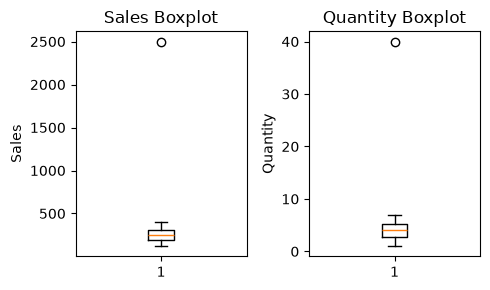

In [37]:
plt.figure(figsize=(5,3))

plt.subplot(1, 2, 1)
plt.boxplot(df["Sales"])
plt.title("Sales Boxplot")
plt.ylabel("Sales")

plt.subplot(1, 2, 2)
plt.boxplot(df["Quantity"])
plt.title("Quantity Boxplot")
plt.ylabel("Quantity")

plt.tight_layout()
plt.show()


In [38]:
filtered_df = outlier_df[
    (~outlier_df["Sales_Outlier"]) &
    (~outlier_df["Quantity_Outlier"])
].copy()

In [40]:
filtered_df

,Transaction_ID,Sales,Quantity,Sales_Outlier,Quantity_Outlier
0,1,120,1,False,False
1,2,150,2,False,False
2,3,180,2,False,False
3,4,200,3,False,False
4,5,220,3,False,False
5,6,240,4,False,False
6,7,260,4,False,False
7,8,280,5,False,False
8,9,300,5,False,False
9,10,350,6,False,False


In [43]:


comparison = pd.DataFrame({
    "Original_Mean": df[features].mean(),
    "Filtered_Mean": filtered_df[features].mean(),
    "Original_Median": df[features].median(),
    "Filtered_Median": filtered_df[features].median(),
    "Original_Std": df[features].std(),
    "Filtered_Std": filtered_df[features].std()
})


In [44]:
comparison

,Original_Mean,Filtered_Mean,Original_Median,Filtered_Median,Original_Std,Filtered_Std
Sales,433.333333,245.454545,250.0,240.0,655.776200,84.304642
Quantity,6.833333,3.818182,4.0,4.0,10.590161,1.834022


Question 2: Z-Score Detection and Statistical Interpretation
A manufacturing company measures the operating temperature of its machines. The engineering team suspects that some observations are unusually far from the average.

import numpy as np
import pandas as pd

df = pd.DataFrame({
    "Machine_ID": range(1, 13),
    "Temperature": [68, 70, 69, 72, 71, 73,
                    70, 74, 68, 72, 71, 115],
    "Pressure": [30, 32, 31, 33, 32, 34,
                 31, 33, 32, 35, 34, 60]
})
A. Calculate the Z-score for each observation in Temperature and Pressure using scipy.stats.zscore. Flag values whose absolute Z-score exceeds 3, display the results, and visualize the scores with scatterplots and horizontal threshold lines.

B. Repeat the analysis using thresholds of 2 and 3. Compare the number of flagged observations and explain how changing the threshold affects sensitivity to unusual values. Discuss why an extreme value can distort the mean and standard deviation used by the Z-score method

In [59]:
from scipy.stats import zscore
df1 = pd.DataFrame({
    "Machine_ID": range(1, 13),
    "Temperature": [68, 70, 69, 72, 71, 73,
                    70, 74, 68, 72, 71, 115],
    "Pressure": [30, 32, 31, 33, 32, 34,
                 31, 33, 32, 35, 34, 60]
})


In [60]:
df

,Machine_ID,Temperature,Pressure
0,1,68,30
1,2,70,32
2,3,69,31
3,4,72,33
4,5,71,32
5,6,73,34
6,7,70,31
7,8,74,33
8,9,68,32
9,10,72,35


In [61]:
df1.shape

(12, 3)